![Banner](../images/09_11_banner_rs_foundation_models.png)


# Self-supervised pretraining for Sentinel-2 crop mapping

Labels are the expensive part of remote sensing classification, while unlabeled imagery arrives every few days.


## Overview

Self-supervised learning (SSL) uses that unlabeled imagery to train an encoder **without any labels**, and a small labeled set is then enough to turn the encoder's features into a classifier. This tutorial pretrains encoders on unlabeled Sentinel-2 chips over the Iowa corn belt study area (the `Corn_belt` AOI, about 30 km × 29 km), then measures how useful their features are for crop-type mapping with the USDA Cropland Data Layer (CDL) as the reference.

The imagery is the 20 m Sentinel-2 L2A cube already built by `../09_09_image_classification/09_09_03_02_spatio_temporal_and_multi_sensor_crop_mapping_sentinel_2_sentinel_1_and_landsat_time_series_2020_to_2025.ipynb` and cached in `Data/08_remote_sensing/08_09_image_classification/Corn_belt/cache_20m`: 34 clear-sky acquisitions from May to October, 2020 to 2025, with 10 bands (blue, green, red, three red-edge bands, two NIR bands and two SWIR bands) as surface reflectance, and clouds, shadows and snow set to missing. The CDL labels for every year are cached on the same grid and recoded to six classes: corn, soybeans, grass/pasture, developed, wetland/forest and other.

Four pretraining recipes are compared: **SimCLR** with ordinary image augmentations, **SimCLR and MoCo with seasonal views** (two dates of the same place, as in SeCo), and a **masked autoencoder** (MAE). Each encoder is frozen and scored with a **linear probe** on held-out geography. A random-weights encoder and the plain band means of each chip are the baselines. The last part shows how pretraining on the test area itself leaks information into the evaluation, and how to check for it.

**A CUDA GPU is required.** Each pretraining run takes a few minutes on a workstation GPU; on a CPU the notebook would take hours, so the setup cell stops if no GPU is found.


## Core concepts

### Learning objectives

1. Read the cached Sentinel-2 cube and CDL labels, cut the scene into chips, and hold out the eastern third of the AOI with a buffer.
2. Pretrain a ResNet-18 with SimCLR and MoCo, using ordinary augmentations and seasonal views from the same growing season.
3. Pretrain a convolutional masked autoencoder and inspect its reconstructions.
4. Freeze each encoder, score the embeddings with a linear probe on held-out geography, and compare them with a random-weights encoder and with band means.
5. Measure label efficiency and view the embeddings with t-SNE (and UMAP when it is installed).
6. Check the distance between pretraining chips and test chips, and compare a clean run with one pretrained on the test area.
7. Save the encoders and write a map of the learned features.

### Contents

1. Workflow and GeoLattice functions
2. Why self-supervised learning for remote sensing
3. Contrastive learning
4. Masked image modelling
5. Evaluation with frozen embeddings
6. Leakage between pretraining and test areas
7. Export the encoders and an embedding map
8. Interpretation and limitations


## Workflow and GeoLattice functions

1. Read the cached Sentinel-2 cube and CDL labels, cut the scene into 16 × 16 pixel chips (320 m), and hold out the eastern third of the AOI for testing with `geographic_holdout`.
2. Contrastive learning: build a ResNet-18 encoder with `make_encoder`, look at the `nt_xent_loss`, and pretrain with `pretrain_contrastive` (SimCLR and MoCo).
3. Masked image modelling: build a convolutional masked autoencoder with `build_mae` and pretrain it with `pretrain_masked`.
4. Evaluation: freeze each encoder, compute features with `extract_embeddings`, score them with `linear_probe` and `classification_report`, measure label efficiency, and map the embeddings with t-SNE (and UMAP when it is installed).
5. Leakage: measure the distance between pretraining chips and test chips with `check_geographic_overlap`, and compare a clean run with one pretrained on the test area.
6. Save the encoders and write a map of the learned features as a Cloud-Optimized GeoTIFF with `geolattice.rsense.write`.

All SSL functions live in `geolattice.rsense.classify.image_classification` (imported as `ic`); PyTorch is needed for the encoders (`pip install "geolattice[rsense-dl]"`).


## Why self-supervised learning for remote sensing

Three properties of satellite imagery make SSL attractive:

- **Labels are scarce, pixels are not.** Sentinel-2 alone images every field on Earth every five days, but crop-type labels need field visits or government surveys such as the CDL, which exists only for the United States and only after the season. Most of the archive is unlabeled.
- **ImageNet features fit poorly.** Encoders pretrained on photographs expect three RGB channels, objects seen from the side, and centimetre-scale detail. Sentinel-2 has 10 to 13 bands, a nadir view with no "up", and 10 to 60 m pixels. Pretraining on the target sensor learns filters for red-edge and SWIR reflectance that ImageNet never saw.
- **Time gives free augmentations.** Contrastive learning needs two "views" of the same thing that should map to similar features. With photographs, the views are made by cropping and colour jitter. A satellite revisits the same place, so two **acquisitions of the same location on different dates** are natural views: the land is the same, while illumination, atmosphere and crop stage change. This is the idea of Seasonal Contrast (SeCo, Mañas et al. 2021) and of later temporal SSL methods.

Seasonal views need care. If the two dates come from different years, a field can switch from corn to soybeans between them, and the encoder is then trained to ignore exactly the difference that crop mapping needs. In this notebook both views of a pair are therefore drawn from **the same growing season**, so the crop is the same and only its stage differs.


### Imports, paths, and experiment settings

This cell imports PyTorch for the encoders, scikit-learn for the 2-D embedding views, and the GeoLattice image-classification module. It finds the repository so the paths work from any folder inside it, checks that the cached cube and labels are on the local drive, and stops if no CUDA GPU is available. `CHIP` sets the chip size: 16 pixels at 20 m is 320 m, smaller than a typical Iowa field (about 800 m on a side), so most chips are dominated by one crop. `MIN_CLEAR` and `MIN_PURITY` decide which chips are clear enough to use and pure enough to label. `BUFFER_M` is the gap kept free between the pretraining/training area and the test area.


**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
from pathlib import Path  # file paths
import copy  # copy a network
import os  # CPU count
import sys  # Python import path
import time  # timing

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import torch  # PyTorch: encoders and pretraining
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled arrays (the Sentinel-2 cube)
from matplotlib.colors import ListedColormap  # class colours
from sklearn.decomposition import PCA  # colours for the embedding map
from sklearn.manifold import TSNE  # 2-D view of the embeddings
from torch.utils.data import DataLoader, Dataset  # feed chips to PyTorch in batches

# Prefer this checkout's code when launched from the repository.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").exists() and (p / "src" / "rsense").is_dir()), None)
if ROOT is not None:  # a checkout was found
    sys.path.insert(0, str(ROOT / "src"))  # import GeoLattice from its src folder

import geolattice.rsense as rs  # GeoLattice remote sensing (raster writing)
import geolattice.rsense.classify.image_classification as ic  # chip classification and SSL tools

if ROOT is None:  # not started inside the repository
    raise FileNotFoundError("Start Jupyter from the GeoLattice checkout or one of its subdirectories")  # stop with a clear message
# this notebook's folder
NOTEBOOK_DIR = ROOT / "Tutorials" / "notebooks" / "08_remote_sensing" / "09_11_foundations_models"
# the corn belt study area, shared with chapter 08_09
DATA_DIR = NOTEBOOK_DIR / "../../../../Data/08_remote_sensing/08_09_image_classification" / "Corn_belt"
CACHE_DIR = DATA_DIR / "cache_20m"  # cubes on the 20 m grid, built by notebook 09_09_03_02
S2_PATH = CACHE_DIR / "s2_20m.nc"  # Sentinel-2 reflectance cube (time, band, y, x)
LABEL_PATH = CACHE_DIR / "labels_20m.nc"  # CDL classes per year on the same grid
OUTPUT_DIR = DATA_DIR / "outputs" / "self_supervised"  # encoders and maps written here
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # create it if needed

# Both cubes are read from the local drive. Notebook 09_09_03_02 builds them from the
# Sentinel_2 scene folders and the CDL rasters (which its download scripts fetch).
missing = [str(p) for p in (S2_PATH, LABEL_PATH) if not p.exists()]  # inputs not found
if missing:  # stop early with the list of missing files
    # stop and name the notebook that builds them
    raise FileNotFoundError("Run 09_09_image_classification/09_09_03_02_spatio_temporal_and_multi_sensor_crop_mapping_sentinel_2_sentinel_1_and_landsat_time_series_2020_to_2025.ipynb first "
                            "to build: " + ", ".join(missing))

if not torch.cuda.is_available():  # pretraining several encoders is impractical on a CPU
    raise RuntimeError("This notebook needs a CUDA GPU (torch.cuda.is_available() is False)")  # stop with a clear message
DEVICE = "cuda"  # every network runs on the GPU

CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # CDL classes
COLORS = ["#e6c229", "#2a9d3c", "#b9e08b", "#d7301f", "#1f5fbf", "#7f7f7f"]  # one colour per class
K = len(CLASSES)  # number of classes
CHIP = 16  # chip width in 20 m pixels (320 m)
MIN_CLEAR = 0.98  # share of cloud-free pixels a chip needs on a date
MIN_PURITY = 0.6  # share of the chip the majority CDL class must cover to label it
BUFFER_M = 1600  # metres kept free between the training area and the test area
TEST_FRACTION = 1 / 3  # eastern share of the AOI held out for testing
EPOCHS = 100  # pretraining epochs for every method
BATCH = 256  # chips per pretraining batch
SEED = 7  # random seed
ic.set_seed(SEED)  # same initial weights and shuffles on every run
torch.set_num_threads(min(8, os.cpu_count() or 1))  # CPU threads for data preparation
print("GeoLattice checkout:", ROOT)  # repository path
print("PyTorch:", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))  # versions and device
print("Output folder:", OUTPUT_DIR)  # output folder


GeoLattice checkout: /home/zia207/Github/GeoLattice
PyTorch: 2.14.0+cu132 | GPU: NVIDIA RTX A5500 Laptop GPU
Output folder: /home/zia207/Github/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_09_image_classification/data/Corn_belt/outputs/self_supervised


### Read the Sentinel-2 cube and the CDL labels

The cube holds surface reflectance (digital numbers × 0.0001, with the processing-baseline offset already removed) for 34 dates on one 20 m grid; the 10 m bands were averaged onto it. Clouds, cloud shadows, cirrus and snow from the scene classification layer are already set to missing (NaN). The label file holds one CDL map per year, recoded to the six classes, with `-1` where the CDL has no data. Both are read fully into memory (about 3 GB).


In [2]:
s2 = xr.open_dataarray(S2_PATH).load()  # (time, band, y, x) surface reflectance, NaN = cloud
labels = xr.open_dataset(LABEL_PATH).load()  # CDL classes per year on the same grid
CRS = labels.spatial_ref.attrs["crs_wkt"]  # map projection (UTM zone 15N)
s2 = s2.rio.write_crs(CRS)  # attach it to the cube

BANDS = [str(b) for b in s2.band.values]  # band names
DATES = pd.DatetimeIndex(s2.time.values)  # acquisition dates
YEARS = [int(y) for y in labels.year.values]  # CDL years
T, C, H, W = s2.shape  # dates, bands, rows, columns
print(f"Sentinel-2 cube: {T} dates x {C} bands x {H} x {W} pixels at 20 m, {s2.nbytes / 1e9:.1f} GB")  # cube size
print("bands:", BANDS)  # band order used by every network
# number of dates in each year
print("dates per year:", pd.Series(DATES.year).value_counts().sort_index().to_dict())
cloud = np.isnan(s2.isel(band=0).values).mean(axis=(1, 2))  # masked share of every date
print(f"masked pixels per date: median {np.median(cloud):.1%}, max {cloud.max():.1%}")  # cloud masking summary

Sentinel-2 cube: 34 dates x 10 bands x 1456 x 1516 pixels at 20 m, 3.0 GB
bands: ['blue', 'green', 'red', 'rededge1', 'rededge2', 'rededge3', 'nir', 'nir08', 'swir16', 'swir22']
dates per year: {2020: 5, 2021: 6, 2022: 5, 2023: 6, 2024: 6, 2025: 6}
masked pixels per date: median 0.0%, max 4.4%


### Cut the scene into chips and measure cloud cover

The grid is cut into non-overlapping 16 × 16 pixel chips. For every chip and date, the share of fully valid pixels (all ten bands present) decides whether that chip-date can be used. For every chip and year, the CDL pixels are counted per class: the majority class becomes the chip's label for that year, and its share is the chip's **purity**. A chip on a field boundary has a low purity and is left out of the labelled evaluation set, although it still serves for pretraining, where no label is needed. The chips are stored as 16-bit floats to halve the memory.


In [3]:
NR, NC = H // CHIP, W // CHIP  # chip rows and columns that fit in the grid
cube = s2.values[:, :, :NR * CHIP, :NC * CHIP]  # crop the grid to whole chips
# (time, band, row, y, col, x) -> (chip, time, band, y, x); chip index = row * NC + col
chips = cube.reshape(T, C, NR, CHIP, NC, CHIP).transpose(2, 4, 0, 1, 3, 5).reshape(NR * NC, T, C, CHIP, CHIP)
clear = np.isfinite(chips).all(axis=2).mean(axis=(-2, -1))  # (chip, date) share of valid pixels
chips = chips.astype("float16")  # halve the memory; reflectance needs no more precision
del cube  # free the cropped float32 copy

xs = s2.x.values[:NC * CHIP].reshape(NC, CHIP).mean(axis=1)  # x of every chip centre
ys = s2.y.values[:NR * CHIP].reshape(NR, CHIP).mean(axis=1)  # y of every chip centre
gx, gy = np.meshgrid(xs, ys)  # centre coordinates on the chip grid
coords = np.c_[gx.ravel(), gy.ravel()]  # (chip, 2) map coordinates in metres

cdl = labels.cdl.values[:, :NR * CHIP, :NC * CHIP]  # CDL classes cropped the same way
# (year, row, y, col, x) -> (chip, year, pixels)
cdl = cdl.reshape(len(YEARS), NR, CHIP, NC, CHIP).transpose(1, 3, 0, 2, 4).reshape(NR * NC, len(YEARS), -1)
counts = np.stack([(cdl == k).sum(axis=-1) for k in range(K)], axis=-1)  # (chip, year, class) pixel counts
labelled = counts.sum(axis=-1)  # pixels with a CDL class
major = counts.argmax(axis=-1)  # majority class of every chip and year
purity = counts.max(axis=-1) / np.maximum(labelled, 1)  # share of the majority class
year_index = np.asarray(DATES.year) - YEARS[0]  # CDL year of every date

usable = clear >= MIN_CLEAR  # chip-dates clear enough to use
print(f"{NR} x {NC} = {NR * NC} chips of {CHIP} x {CHIP} pixels ({CHIP * 20} m), "  # number and size of the chips
      f"{chips.nbytes / 1e9:.1f} GB as float16")
print(f"clear chip-dates: {usable.sum()} of {usable.size} ({usable.mean():.0%})")  # how many chip-dates are clear
print(f"chips with purity >= {MIN_PURITY}: {(purity >= MIN_PURITY).mean():.0%} of chip-years")  # how many chips can be labelled

91 x 94 = 8554 chips of 16 x 16 pixels (320 m), 1.5 GB as float16
clear chip-dates: 289677 of 290836 (100%)
chips with purity >= 0.6: 81% of chip-years


### Hold out an eastern test region with a buffer

A random split of chips would put test chips right next to training chips from the same fields, so the test score would mostly measure memory of nearby pixels. Instead `geographic_holdout` puts every chip whose centre falls inside a test rectangle (the eastern third of the AOI) into the test set. A further 1.6 km strip on the western side of that boundary is dropped from training, because fields, soils and farm management are spatially autocorrelated across the boundary. The same western area serves for **both** pretraining and probe training, so neither the encoder nor the probe ever sees the test area. The section on leakage below checks this and shows what happens without it.


train area 5187 chips | buffer 455 chips | test area 2912 chips


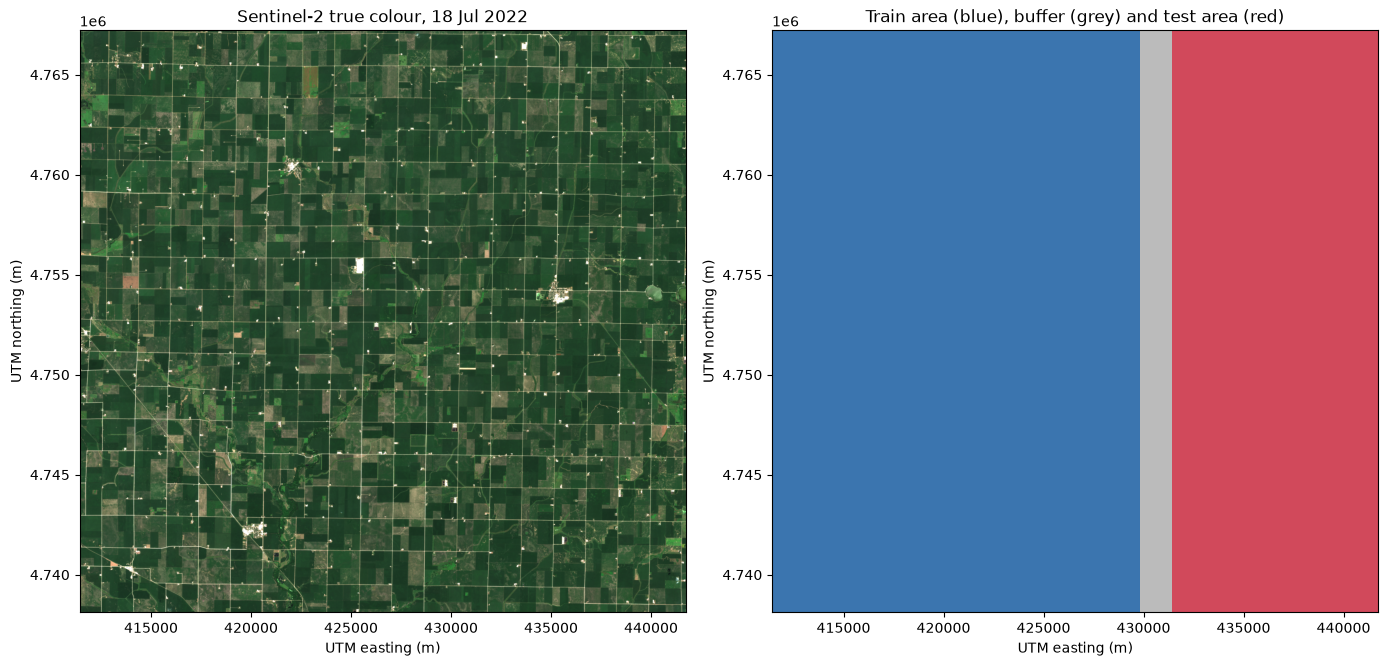

In [4]:
x_split = xs.min() + (1 - TEST_FRACTION) * np.ptp(xs)  # x of the test-area boundary
test_bounds = (x_split, ys.min(), xs.max(), ys.max())  # xmin, ymin, xmax, ymax of the test area
split = ic.geographic_holdout(coords, test_bounds)  # chips inside the box are test, the rest train
train_loc = split.train[coords[split.train, 0] < x_split - BUFFER_M]  # training chips outside the buffer
buffer_loc = np.setdiff1d(split.train, train_loc)  # chips in the buffer strip (never used)
test_loc = split.test  # chips of the test area
print(f"train area {len(train_loc)} chips | buffer {len(buffer_loc)} chips | test area {len(test_loc)} chips")  # chips per region

region = np.zeros(NR * NC, "int8")  # 0 = train area
region[buffer_loc], region[test_loc] = 1, 2  # 1 = buffer, 2 = test area

t_show = int(np.argmax(usable.mean(axis=0) * np.asarray(DATES.month == 7)))  # clearest July date
rgb = s2.isel(time=t_show).sel(band=["red", "green", "blue"]).values.transpose(1, 2, 0)  # true colour
ext = [s2.x.min().item(), s2.x.max().item(), s2.y.min().item(), s2.y.max().item()]  # map extent
fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))  # two panels
ax[0].imshow(np.clip(np.nan_to_num(rgb) / 0.15, 0, 1), extent=ext)  # true colour, 0-15 % reflectance
ax[0].set_title(f"Sentinel-2 true colour, {DATES[t_show]:%d %b %Y}")  # title
cmap_region = ListedColormap(["#3b75af", "#bbbbbb", "#d1495b"])  # train, buffer, test
# region map: west train, buffer, east test
ax[1].imshow(region.reshape(NR, NC), cmap=cmap_region, vmin=-0.5, vmax=2.5,
             extent=ext, interpolation="nearest")  # the three regions on the chip grid
ax[1].set_title("Train area (blue), buffer (grey) and test area (red)")  # title
for a in ax:  # both panels
    a.set_xlabel("UTM easting (m)"); a.set_ylabel("UTM northing (m)")  # axis labels
plt.tight_layout(); plt.show()  # arrange and draw

### Seasonal views: the same field on different dates

Before training, every band is standardised with the mean and standard deviation of clear training-area chips, and the few remaining missing pixels are set to zero (the band mean). The figure shows what a seasonal pair looks like. Each row is one chip through one growing season: the bare soil of May, the closed canopy of July and August, and the senescence of September and October. The mid-June scene is hazy: it passed the cloud mask, but thin haze brightens and blues every band. For a contrastive model, any two of these dates are a **positive pair**: two pictures of the same land, and haze, illumination and crop stage are exactly the differences the encoder is asked to ignore. Corn and soybeans differ mainly in the timing and depth of this cycle, which is why both views of a pair are taken from the same year.


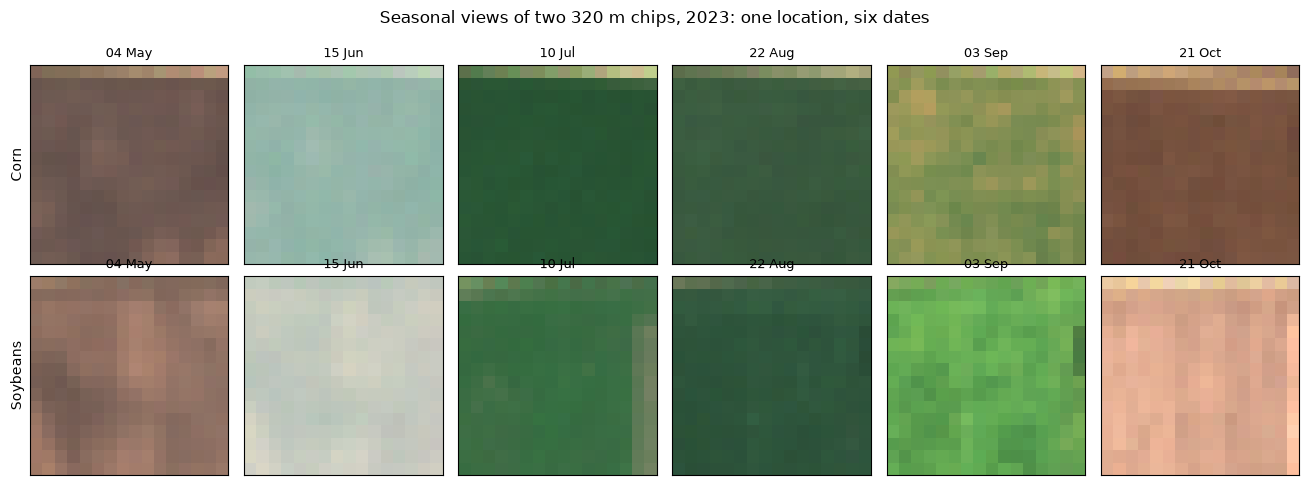

In [5]:
rng = np.random.default_rng(SEED)  # random generator for sampling
pairs = np.argwhere(usable[train_loc])  # (chip, date) positions of clear training chips
pick = pairs[rng.choice(len(pairs), 4000, replace=False)]  # a random sample of them
sample = chips[train_loc[pick[:, 0]], pick[:, 1]].astype("float32")  # (4000, band, y, x)
MEAN = np.nanmean(sample, axis=(0, 2, 3)).reshape(-1, 1, 1)  # per-band mean
STD = np.nanstd(sample, axis=(0, 2, 3)).reshape(-1, 1, 1)  # per-band standard deviation


def normalize(x):  # standardise chips band by band; missing pixels become 0 (the mean)
    return np.nan_to_num((np.asarray(x, "float32") - MEAN) / STD)  # (x - mean) / std, NaN -> 0


def chip_rgb(x):  # true-colour image of one chip (reflectance, not standardised)
    return np.clip(np.nan_to_num(np.asarray(x, "float32")[[2, 1, 0]].transpose(1, 2, 0)) / 0.15, 0, 1)  # red, green, blue scaled 0-15 % reflectance


SHOW_YEAR = 2023  # season shown in the figure
season = np.flatnonzero(DATES.year == SHOW_YEAR)  # its dates
yi = SHOW_YEAR - YEARS[0]  # its CDL index
examples = []  # one corn chip and one soybean chip, clear on as many dates as possible
for k in (0, 1):  # corn, soybeans
    pure = (major[train_loc, yi] == k) & (purity[train_loc, yi] > 0.95)  # pure chips of that class
    n_clear = usable[train_loc][:, season].sum(axis=1)  # clear dates of each chip in the season
    examples.append(train_loc[np.argmax(np.where(pure, n_clear, -1))])  # the pure chip clear most often
fig, ax = plt.subplots(2, len(season), figsize=(2.2 * len(season), 4.8))  # one panel per date
for r, loc in enumerate(examples):  # each example chip
    for c, t in enumerate(season):  # each date of the season
        ax[r, c].imshow(chip_rgb(chips[loc, t]), interpolation="nearest")  # the chip on that date
        ax[r, c].set_title(f"{DATES[t]:%d %b}", fontsize=9)  # date
        ax[r, c].set_xticks([]); ax[r, c].set_yticks([])  # no ticks
    ax[r, 0].set_ylabel(CLASSES[major[loc, yi]])  # CDL class of the chip
fig.suptitle(f"Seasonal views of two 320 m chips, {SHOW_YEAR}: one location, six dates", y=1.0)  # overall title
plt.tight_layout(); plt.show()  # arrange and draw

## Contrastive learning

### The NT-Xent loss

SimCLR (Chen et al. 2020) passes two views of every image through the encoder and a small projection head, giving feature vectors $z_i$ and $z_j$. The normalized-temperature cross-entropy (NT-Xent) loss treats the matching view as the correct class among all $2N - 2$ other views in the batch:

$$\ell_{i,j} = -\log \frac{\exp(\mathrm{sim}(z_i, z_j)/\tau)}{\sum_{k \ne i} \exp(\mathrm{sim}(z_i, z_k)/\tau)}$$

where $\mathrm{sim}$ is cosine similarity and $\tau$ the temperature. The loss falls when the two views of one chip are closer to each other than to every other chip in the batch. `nt_xent_loss` implements it; the cell below shows that matched views give a much lower loss than shuffled ones, and that a lower temperature sharpens the difference.


In [6]:
torch.manual_seed(SEED)  # reproducible random vectors
z1 = torch.randn(256, 64)  # features of 256 "chips", view 1
z2_match = z1 + 0.3 * torch.randn(256, 64)  # view 2: the same chips plus noise
z2_shuffled = z2_match[torch.randperm(256)]  # view 2 paired with the wrong chips
rows = []  # one row per temperature
for tau in (0.1, 0.2, 0.5):  # three temperatures
    rows.append({"temperature": tau,  # loss of matched and shuffled pairs
                 "matched views": float(ic.nt_xent_loss(z1, z2_match, tau)),
                 "shuffled views": float(ic.nt_xent_loss(z1, z2_shuffled, tau)),
                 "chance level, log(2N - 1)": float(np.log(2 * 256 - 1))})
pd.DataFrame(rows).set_index("temperature").round(3)  # show the table

,matched views,shuffled views,"chance level, log(2N - 1)"
temperature,,,
0.1,0.074,9.564,6.236
0.2,1.815,6.560,6.236
0.5,4.362,6.260,6.236


### Pretraining datasets: augmented views and seasonal views

Two PyTorch datasets feed the pretraining. Both draw **one item per training-area chip location**, so every method sees the same number of chips per epoch:

- `SingleDateChips` returns one clear date of a location, chosen at random each time. `pretrain_contrastive` then makes the two views itself with GeoLattice `OverheadAugment`: a random 90° rotation or flip (valid because overhead images have no "up"), a random 80 % crop resized back, and mild brightness, contrast and noise jitter. The masked autoencoder uses the same dataset.
- `SeasonalPairs` returns two different clear dates of the same location from one randomly chosen year, each with its own rotation, flip and crop. A batch that is a `(view1, view2)` pair is used by `pretrain_contrastive` as is: this is the SeCo-style recipe.

Only locations with at least two clear dates in some year are kept, and new dates are drawn every epoch, so the pairs keep changing.


In [7]:
class SingleDateChips(Dataset):  # PyTorch dataset of single-date chips
    """One random clear date of each location, standardised, as a (band, y, x) tensor."""

    def __init__(self, locs, seed=SEED):  # store the locations and their usable dates
        self.locs = np.asarray(locs)  # chip locations
        self.dates = [np.flatnonzero(usable[l]) for l in self.locs]  # their clear dates
        self.rng = np.random.default_rng(seed)  # date sampler

    def __len__(self):  # number of items per epoch
        return len(self.locs)  # one item per location

    def __getitem__(self, i):  # one item
        t = self.rng.choice(self.dates[i])  # a random clear date
        return torch.from_numpy(normalize(chips[self.locs[i], t]))  # the standardised chip


class SeasonalPairs(Dataset):  # PyTorch dataset of seasonal positive pairs
    """Two clear dates of the same location and season (SeCo-style views), each randomly flipped and cropped."""

    def __init__(self, locs, seed=SEED):  # store the locations and their usable dates
        self.locs, self.seasons = [], []  # usable locations and their clear dates per year
        for l in locs:  # every candidate location
            by_year = [np.flatnonzero(usable[l] & (year_index == y)) for y in range(len(YEARS))]  # clear dates of each year
            by_year = [d for d in by_year if len(d) >= 2]  # seasons with at least two clear dates
            if by_year:  # keep the location if one season qualifies
                self.locs.append(l); self.seasons.append(by_year)  # keep the location and its seasons
        self.aug = ic.OverheadAugment(dihedral=True, crop=0.8, seed=seed)  # geometric augmentation
        self.rng = np.random.default_rng(seed)  # season and date sampler

    def __len__(self):  # number of items per epoch
        return len(self.locs)  # one item per location

    def __getitem__(self, i):  # one item
        season = self.seasons[i][self.rng.integers(len(self.seasons[i]))]  # a random season
        t1, t2 = self.rng.choice(season, 2, replace=False)  # two different dates in it
        v1 = self.aug(torch.from_numpy(normalize(chips[self.locs[i], t1])))[0]  # view 1
        v2 = self.aug(torch.from_numpy(normalize(chips[self.locs[i], t2])))[0]  # view 2
        return v1, v2  # a positive pair


def make_loader(dataset):  # shuffled batches; drop_last keeps every batch full for the loss
    return DataLoader(dataset, batch_size=BATCH, shuffle=True, drop_last=True,  # batches of BATCH chips
                      generator=torch.Generator().manual_seed(SEED))


pretrain_loc = train_loc[[len(np.flatnonzero(usable[l])) >= 2 for l in train_loc]]  # chips with 2+ clear dates
single_ds = SingleDateChips(pretrain_loc)  # single-date chips
pair_ds = SeasonalPairs(pretrain_loc)  # seasonal pairs
print(f"pretraining locations: {len(single_ds)} (single date), {len(pair_ds)} (seasonal pairs); "  # dataset sizes
      f"{len(pair_ds) // BATCH} batches of {BATCH} per epoch")
v1, v2 = pair_ds[0]  # one example pair
print("one seasonal pair:", tuple(v1.shape), tuple(v2.shape))  # (band, y, x) each

pretraining locations: 5187 (single date), 5187 (seasonal pairs); 20 batches of 256 per epoch
one seasonal pair: (10, 16, 16) (10, 16, 16)


### Make the encoder and pretrain with SimCLR and MoCo

`make_encoder("resnet18", in_channels=10)` returns a torchvision ResNet-18 whose first convolution takes the ten Sentinel-2 bands and whose classification head is removed, so the network maps a chip to a 512-number feature vector. No ImageNet weights are loaded: everything is learned from the corn belt chips. ResNet-18 was designed for 224-pixel photographs and shrinks its input 32 times; on a 16-pixel chip the stem convolution and the max-pooling layer would reduce the chip to 4 × 4 pixels before the first residual block. Replacing the max-pooling layer with an identity keeps twice the spatial detail, the usual adjustment for small chips (as for CIFAR images). An untrained copy is kept as the **random-weights baseline**; a randomly initialised network already gives features that a linear probe can use, so pretraining has to beat it to be worth anything.

`pretrain_contrastive` adds a two-layer projection head (512 → 512 → 64) and trains both with AdamW. Three runs are made with the same encoder, epochs and learning rate:

- **SimCLR, augmented views**: two augmentations of one date (the classic recipe).
- **SimCLR, seasonal views**: two dates of one season (SeCo-style).
- **MoCo, seasonal views**: the same pairs with MoCo v2: the second view goes through a slowly updated momentum copy of the encoder, and the negatives come from a queue of 4,096 earlier features instead of the current batch, which helps when batches are small.

The projection head is discarded afterwards; the encoder output is what is evaluated.


In [8]:
def new_encoder():  # a fresh ResNet-18 for 10 bands with the same initial weights every time
    torch.manual_seed(SEED)  # identical initialisation for every method
    enc = ic.make_encoder("resnet18", in_channels=C)  # head removed: chip -> 512 features
    enc.maxpool = torch.nn.Identity()  # no max pooling: keep detail on 16-pixel chips
    return enc  # the encoder


encoders, history, minutes = {}, {}, {}  # trained encoders, loss curves and run times
encoders["Random weights"] = new_encoder().to(DEVICE)  # baseline: never trained
runs = {  # name -> (method, dataset)
    "SimCLR, augmented views": ("simclr", single_ds),
    "SimCLR, seasonal views": ("simclr", pair_ds),
    "MoCo, seasonal views": ("moco", pair_ds),
}
for name, (method, dataset) in runs.items():  # each contrastive recipe
    t0 = time.time()  # start the timer
    encoders[name], hist = ic.pretrain_contrastive(  # contrastive pretraining
        new_encoder(), make_loader(dataset), in_channels=C, method=method, epochs=EPOCHS,
        lr=1e-3, temperature=0.2, proj_dim=64, queue_size=4096, momentum=0.99,
        device=DEVICE, seed=SEED, verbose=False)  # pretrain without labels
    history[name], minutes[name] = hist["loss"], (time.time() - t0) / 60  # keep the loss curve and time
    print(f"{name:26s} {EPOCHS} epochs in {minutes[name]:.1f} min, "  # run time and loss
          f"loss {hist['loss'][0]:.3f} -> {hist['loss'][-1]:.3f}")

SimCLR, augmented views    100 epochs in 2.2 min, loss 3.691 -> 1.969


SimCLR, seasonal views     100 epochs in 1.7 min, loss 6.211 -> 3.679


MoCo, seasonal views       100 epochs in 1.5 min, loss 7.259 -> 6.713


### Pretraining loss curves

The loss of each run falls as the encoder learns to tell chips apart. The absolute values of different recipes cannot be compared: seasonal views are harder to match than two crops of the same image, and MoCo scores each chip against 4,096 queued negatives instead of the 510 in a SimCLR batch. A falling, flattening curve only says the pretext task is being learned; the linear probe below says whether the features are useful.


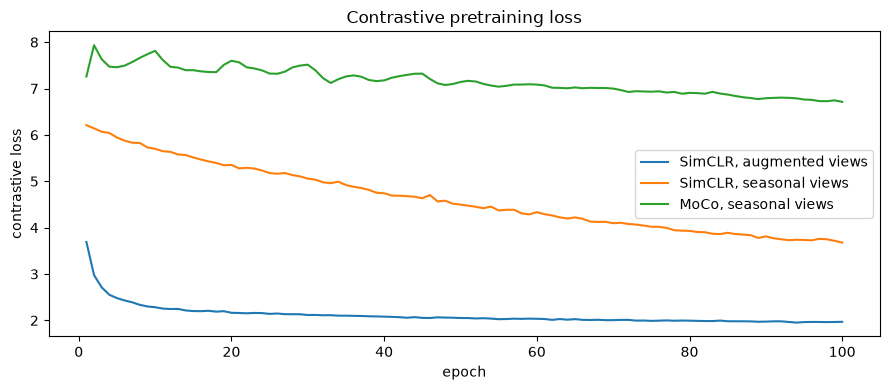

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))  # one panel
for name, loss in history.items():  # each run
    ax.plot(range(1, len(loss) + 1), loss, label=name)  # its loss per epoch
ax.set(xlabel="epoch", ylabel="contrastive loss", title="Contrastive pretraining loss")  # labels
ax.legend(); plt.tight_layout(); plt.show()  # legend, arrange and draw

## Masked image modelling

### Build and pretrain a masked autoencoder

Masked image modelling takes a different route: hide part of the image and train the network to fill it in. MAE (He et al. 2022) does this with a Vision Transformer; SatMAE and Scale-MAE adapt it to satellite imagery with temporal, spectral and scale-aware position encodings. `build_mae` gives a small **convolutional** masked autoencoder that runs on 16-pixel chips: a three-layer encoder (two stride-2 convolutions, 256 output channels) and a two-layer transposed-convolution decoder.

During training, `random_mask` hides 60 % of the 4 × 4 pixel patches of each chip (`patch=4`, `mask_ratio=0.6`), the encoder sees only the visible part, and the loss is the mean squared error on the **masked** pixels only, so copying the input does not help. To fill a hidden patch, the network has to learn how bands relate to each other and how fields continue in space. `pretrain_masked` runs the training loop. For linear probing, the encoder's output is averaged over the chip (the model's `features` method), giving 256 numbers per chip.


In [10]:
torch.manual_seed(SEED)  # same initial weights on every run
mae = ic.build_mae(C, width=64, patch=4, mask_ratio=0.6)  # convolutional masked autoencoder (64-128-256 channels)
t0 = time.time()  # start the timer
mae, mae_hist = ic.pretrain_masked(mae, make_loader(single_ds), epochs=EPOCHS, lr=1e-3,  # masked-image pretraining
                                   device=DEVICE, seed=SEED, verbose=False)  # reconstruct masked patches
encoders["Masked autoencoder"] = mae  # its encoder is evaluated with the others
minutes["Masked autoencoder"] = (time.time() - t0) / 60  # run time
print(f"masked autoencoder: {EPOCHS} epochs in {minutes['Masked autoencoder']:.1f} min, "  # run time and loss
      f"loss {mae_hist['loss'][0]:.3f} -> {mae_hist['loss'][-1]:.3f} (standardised units squared)")

masked autoencoder: 100 epochs in 0.4 min, loss 0.622 -> 0.175 (standardised units squared)


### Look at the reconstructions

Each row shows one test-area chip (never seen in pretraining): the original, the input with the masked patches blacked out, the raw reconstruction, and the reconstruction with the visible patches pasted back. The reconstructions are poor as pictures. The loss is computed only on hidden patches, so the visible parts of the raw reconstruction are never trained to match, and many hidden patches are filled with plausible but invented content, such as a bare-soil field or a road where the original has a uniform canopy. With 60 % of a 16-pixel chip hidden, the remaining pixels often do not say what was there. That is expected: the reconstruction is only the pretext task, and the evaluation below shows that the encoder trained this way still yields the most balanced features of all methods. Good features do not require good reconstructions.


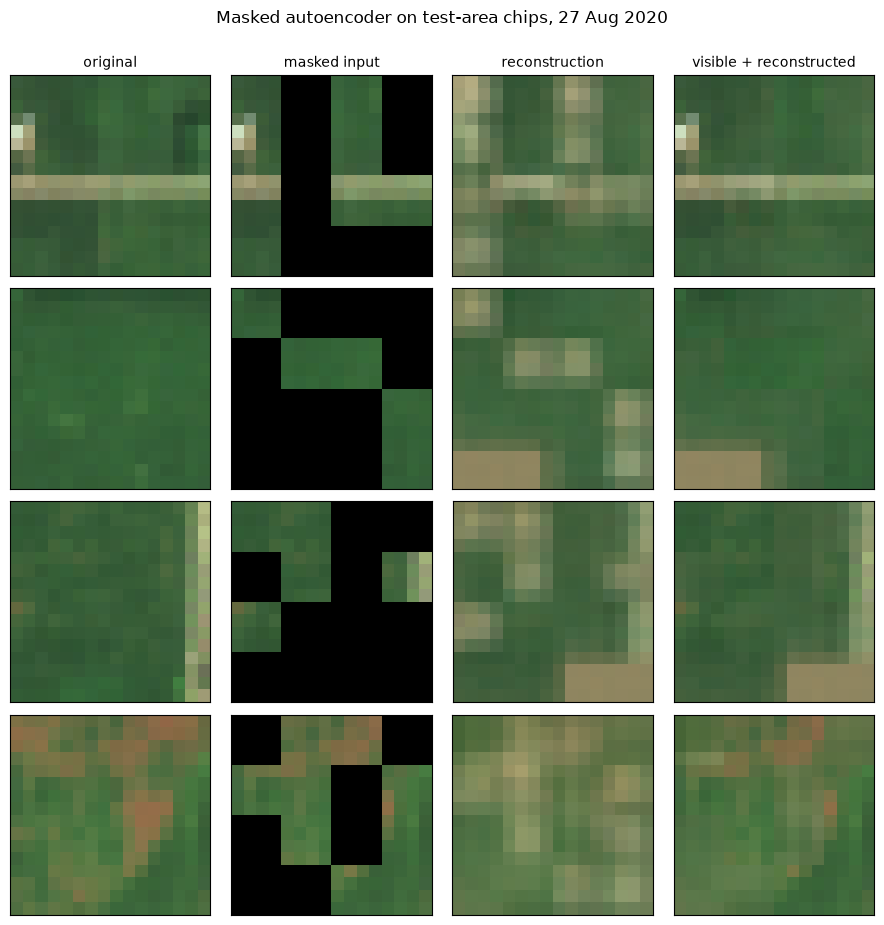

In [11]:
t_peak = int(np.argmax(usable[test_loc].mean(axis=0) * np.asarray(DATES.month == 8)))  # clearest August date
show = test_loc[np.flatnonzero(usable[test_loc, t_peak])[::97][:4]]  # four clear test chips
x = torch.from_numpy(normalize(chips[show, t_peak])).to(DEVICE)  # standardised chips on the GPU
mae.eval()  # evaluation mode
torch.manual_seed(SEED)  # reproducible mask
with torch.no_grad():  # no gradients needed
    _, rec, m = mae(x)  # reconstruction and mask (1 = hidden)
to_refl = lambda a: a.cpu().numpy() * STD + MEAN  # standardised values back to reflectance
panels = {"original": to_refl(x), "masked input": to_refl(x * (1 - m)),  # the four panels per chip
          "reconstruction": to_refl(rec), "visible + reconstructed": to_refl(x * (1 - m) + rec * m)}
fig, ax = plt.subplots(len(show), 4, figsize=(9, 2.3 * len(show)))  # one row per chip
for r in range(len(show)):  # each chip
    for c, (title, arr) in enumerate(panels.items()):  # each panel
        img = chip_rgb(arr[r])  # true colour
        if title == "masked input":  # show hidden patches in black
            img = img * (1 - m[r, 0].cpu().numpy()[..., None])  # black out the hidden patches
        ax[r, c].imshow(img, interpolation="nearest")  # draw it
        ax[r, c].set_xticks([]); ax[r, c].set_yticks([])  # no ticks
        if r == 0:  # titles on the first row
            ax[r, c].set_title(title, fontsize=10)  # panel title
fig.suptitle(f"Masked autoencoder on test-area chips, {DATES[t_peak]:%d %b %Y}", y=1.0)  # overall title
plt.tight_layout(); plt.show()  # arrange and draw

## Evaluation with frozen embeddings

### Labelled chips from the CDL

The evaluation uses one peak-season image per year: the July or August date with the most clear chips. A chip is labelled with its majority CDL class of that year when it is clear on that date, at least 60 % pure, and at least 90 % covered by CDL data. Chips in the western training area are the probe's training set; chips in the eastern test area are the test set; buffer chips are dropped. Corn and soybeans make up most chips, as they cover about 90 % of the AOI, so per-class F1 and macro F1 are reported next to overall accuracy.


In [12]:
peak_dates = []  # the July/August date with the most clear chips, per year
for y in YEARS:  # every year
    cand = np.flatnonzero((DATES.year == y) & np.isin(DATES.month, [7, 8]))  # its July/August dates
    peak_dates.append(int(cand[np.argmax(usable[:, cand].mean(axis=0))]))  # the clearest one
loc_e, t_e = [], []  # chip and date of every labelled sample
for t in peak_dates:  # each peak date
    yi = year_index[t]  # its CDL year
    ok = usable[:, t] & (purity[:, yi] >= MIN_PURITY) & (labelled[:, yi] >= 0.9 * CHIP * CHIP) & (region != 1)  # clear, pure, labelled, not buffer
    loc_e.append(np.flatnonzero(ok)); t_e.append(np.full(ok.sum(), t))  # keep the qualifying chips
loc_e, t_e = np.concatenate(loc_e), np.concatenate(t_e)  # all samples
y_e = major[loc_e, year_index[t_e]]  # their CDL class
tr, te = region[loc_e] == 0, region[loc_e] == 2  # probe training (west) and test (east) samples
X_eval = normalize(chips[loc_e, t_e])  # standardised chips (sample, band, y, x)

print("peak dates:", ", ".join(f"{DATES[t]:%Y-%m-%d}" for t in peak_dates))  # dates used
pd.DataFrame({"train area (west)": pd.Series(y_e[tr]).value_counts(),  # samples per class and area
              "test area (east)": pd.Series(y_e[te]).value_counts()}).reindex(range(K)).fillna(0).astype(int) \
    .set_index(pd.Index(CLASSES, name="class"))

peak dates: 2020-08-27, 2021-08-17, 2022-07-18, 2023-07-10, 2024-08-31, 2025-07-14


,train area (west),test area (east)
class,,
Corn,14266,8139
Soybeans,9864,6005
Grass/pasture,325,82
Developed,103,49
Wetland/forest,153,2
Other,105,38


### Extract embeddings

`extract_embeddings` runs a frozen encoder over the chips in batches and returns one feature vector per chip: the ResNet-18 encoders give 512 numbers, and for the masked autoencoder it uses the model's `features` method (256 numbers). A non-learned baseline is added: the **band means** of each chip, ten numbers that hold the chip's average spectrum. Any useful encoder has to add something to the plain spectrum, such as texture, field structure, or a better use of the red-edge and SWIR bands.


In [13]:
emb = {"Band means": X_eval.mean(axis=(-2, -1))}  # baseline: the average spectrum of each chip
for name, enc in encoders.items():  # every encoder, frozen
    t0 = time.time()  # start the timer
    emb[name] = ic.extract_embeddings(enc, X_eval, batch_size=512, device=DEVICE)  # (sample, features)
    print(f"{name:26s} {emb[name].shape[1]:4d} features for {len(X_eval)} chips in {time.time() - t0:.1f} s")  # size and time

Random weights              512 features for 39131 chips in 0.9 s


SimCLR, augmented views     512 features for 39131 chips in 0.9 s


SimCLR, seasonal views      512 features for 39131 chips in 0.9 s


MoCo, seasonal views        512 features for 39131 chips in 0.9 s


Masked autoencoder          256 features for 39131 chips in 0.6 s


### Linear probe on held-out geography

`linear_probe` fits a standardised logistic regression on the frozen embeddings of the training area and predicts the test area. A linear classifier cannot build new features, so its score shows how linearly separable the classes already are in each embedding: the standard way to compare SSL encoders. `classification_report` adds overall accuracy, Cohen's kappa and macro F1. The scores answer one question for this AOI and these years: how well the features of each encoder separate the six classes in an area that neither the encoder nor the probe has seen.


In [14]:
names = dict(enumerate(CLASSES))  # class id -> name
reports, rows = {}, {}  # full reports and summary rows
for name, E in emb.items():  # each feature set
    t0 = time.time()  # start the timer
    probe = ic.linear_probe(E[tr], y_e[tr], E[te], y_e[te], C=1.0, max_iter=3000)  # fit on west, predict east
    rep = ic.classification_report(y_e[te], probe["predictions"], labels=list(range(K)), class_names=names)  # accuracy, kappa, F1
    reports[name] = rep  # keep the full report
    rows[name] = {"features": E.shape[1], "overall accuracy": rep["overall_accuracy"],  # summary row
                  "kappa": rep["kappa"], "macro F1": rep["macro_f1"],
                  "corn F1": rep["per_class"].loc["Corn", "f1"],
                  "soybeans F1": rep["per_class"].loc["Soybeans", "f1"],
                  "pretraining (min)": minutes.get(name, 0.0)}
probe_table = pd.DataFrame(rows).T.round(3)  # one row per feature set
probe_table  # show the table

,features,overall accuracy,kappa,macro F1,corn F1,soybeans F1,pretraining (min)
Band means,10.0,0.969,0.939,0.752,0.978,0.967,0.000
Random weights,512.0,0.752,0.491,0.412,0.809,0.682,0.000
"SimCLR, augmented views",512.0,0.929,0.858,0.643,0.941,0.922,2.164
"SimCLR, seasonal views",512.0,0.987,0.974,0.610,0.994,0.990,1.731
"MoCo, seasonal views",512.0,0.984,0.967,0.625,0.989,0.987,1.532
Masked autoencoder,256.0,0.955,0.911,0.844,0.964,0.950,0.385


**Reading the probe table.** The random-weights encoder is far behind the band means, so an untrained ResNet is not a useful feature extractor here: whatever the pretrained encoders achieve comes from pretraining. The two seasonal-view encoders give the highest overall accuracy, close to 99 %, above the band means (about 97 %), with corn and soybean F1 near 0.99. Their macro F1 is lower, though: they separate the two dominant crops very well but fold most grass/pasture, developed and "other" chips into corn or soybeans. Invariance to date is a good bias for crops, whose identity is stable through a season, but those small classes are rare in the pretraining chips and get little room in the feature space. The masked autoencoder is the most balanced, with the best macro F1 (about 0.85), because reconstruction has to keep every kind of surface, not only the common ones. SimCLR with ordinary augmentations sits in between. Wetland/forest has only two pure test chips in the east, so its F1 is undefined, and macro F1 averages the other five classes.


The per-class table of the best SSL encoder shows where the remaining errors are. The minority classes (grass/pasture, developed, wetland/forest) have few pure 320 m chips, so their F1 scores are less stable than those of corn and soybeans.


In [15]:
best = probe_table.drop(index=["Band means", "Random weights"])["macro F1"].astype(float).idxmax()  # best SSL encoder
print("best self-supervised encoder by macro F1:", best)  # its name
display(reports[best]["per_class"].round(3))  # per-class precision, recall, F1 and support
reports[best]["confusion_matrix"]  # rows: CDL reference, columns: prediction

best self-supervised encoder by macro F1: Masked autoencoder


,precision,recall,f1,support
Corn,0.965,0.964,0.964,8139
Soybeans,0.949,0.951,0.950,6005
Grass/pasture,0.687,0.695,0.691,82
Developed,1.000,0.694,0.819,49
Wetland/forest,0.000,0.000,NaN,2
Other,0.733,0.868,0.795,38


predicted,Corn,Soybeans,Grass/pasture,Developed,Wetland/forest,Other
reference,,,,,,
Corn,7843,283,6,0,4,3
Soybeans,263,5710,18,0,5,9
Grass/pasture,9,16,57,0,0,0
Developed,9,5,1,34,0,0
Wetland/forest,0,2,0,0,0,0
Other,3,1,1,0,0,33


### Do the embeddings add to the spectrum?

The band means and the learned embeddings need not compete: a probe can use both. Appending the ten band means to each embedding shows whether the encoder adds information that the average spectrum lacks, such as within-chip texture and field structure. If the combined probe beats the band means alone, the encoder has learned something the spectrum does not carry.


In [16]:
combo = {}  # one row per encoder
for name in encoders:  # every encoder
    E = np.c_[emb[name], emb["Band means"]]  # embedding plus the average spectrum
    p = ic.linear_probe(E[tr], y_e[tr], E[te], max_iter=3000)["predictions"]  # probe on west, predict east
    r = ic.classification_report(y_e[te], p, labels=list(range(K)))  # scores
    combo[f"{name} + band means"] = {"overall accuracy": r["overall_accuracy"], "kappa": r["kappa"],  # summary row
                                     "macro F1": r["macro_f1"]}
combo = pd.DataFrame(combo).T  # as a table
# band-mean baseline next to the combinations
pd.concat([probe_table.loc[["Band means"], ["overall accuracy", "kappa", "macro F1"]].astype(float), combo]).round(3)

,overall accuracy,kappa,macro F1
Band means,0.969,0.939,0.752
Random weights + band means,0.960,0.920,0.545
"SimCLR, augmented views + band means",0.978,0.955,0.696
"SimCLR, seasonal views + band means",0.989,0.977,0.651
"MoCo, seasonal views + band means",0.987,0.975,0.712
Masked autoencoder + band means,0.986,0.971,0.873


Adding any pretrained embedding to the band means raises the overall accuracy above the band means alone, while adding the random encoder lowers it: 512 random features mostly add noise for the probe to fit. The pretrained encoders therefore carry information that the average spectrum does not, most likely the within-chip structure (field edges, roads, field shape) and better combinations of the red-edge and SWIR bands. On macro F1 only the masked autoencoder adds to the band means, which gives the most balanced probe of the notebook; the contrastive embeddings dominate the combined features and inherit their weakness on the small classes.


### Label efficiency

The main promise of SSL is that a good encoder needs **fewer labels**. The probe is refitted on 1 %, 5 %, 20 % and 100 % of the training-area samples (a stratified random subset, at least two chips per class, three repeats) and always scored on the full test area. A pretrained encoder that keeps its macro F1 at 1 % to 5 % of the labels is the useful case in practice: a few hundred labelled chips instead of thousands.


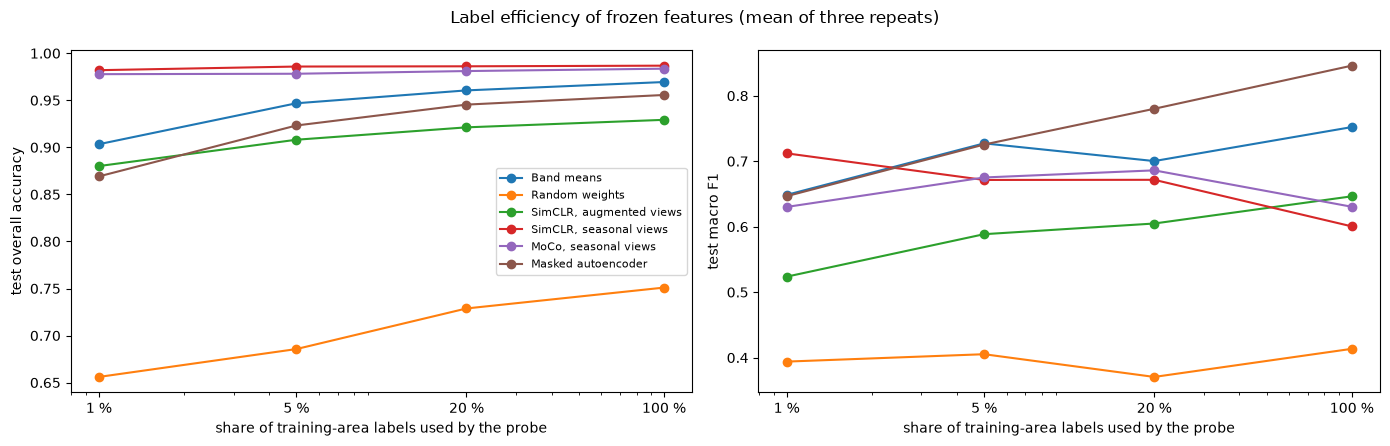

overall accuracy                      macro F1         \
fraction                            0.01   0.05   0.20   1.00     0.01   0.05   
features                                                                        
Band means                         0.903  0.947  0.961  0.969    0.649  0.727   
Masked autoencoder                 0.869  0.923  0.945  0.956    0.647  0.725   
MoCo, seasonal views               0.978  0.978  0.981  0.984    0.630  0.675   
Random weights                     0.656  0.686  0.729  0.751    0.394  0.405   
SimCLR, augmented views            0.880  0.908  0.921  0.929    0.524  0.589   
SimCLR, seasonal views             0.982  0.986  0.986  0.987    0.712  0.671   

                                       
fraction                  0.20   1.00  
features                               
Band means               0.700  0.752  
Masked autoencoder       0.780  0.846  
MoCo, seasonal views     0.686  0.630  
Random weights           0.371  0.413  
SimCLR, augmented views  0.605  0.646  
SimCLR, seasonal views   0.672  0.601

In [17]:
FRACTIONS = [0.01, 0.05, 0.2, 1.0]  # shares of the training labels
tr_idx = np.flatnonzero(tr)  # indices of the training samples


def subsample(frac, seed):  # stratified subset of the training samples
    r = np.random.default_rng(seed)  # random generator for this repeat
    keep = []  # chosen indices
    for k in range(K):  # each class
        idx = tr_idx[y_e[tr_idx] == k]  # its training samples
        n = min(len(idx), max(2, int(round(frac * len(idx)))))  # at least two per class
        keep.append(r.choice(idx, n, replace=False))  # random subset
    return np.concatenate(keep)  # all chosen indices


curve = []  # one row per feature set, fraction and repeat
for name, E in emb.items():  # each feature set
    for frac in FRACTIONS:  # each label share
        for rep_i in range(1 if frac == 1.0 else 3):  # three repeats (one when all labels are used)
            sub = subsample(frac, SEED + rep_i)  # training subset
            p = ic.linear_probe(E[sub], y_e[sub], E[te], max_iter=3000)["predictions"]  # probe
            r = ic.classification_report(y_e[te], p, labels=list(range(K)))  # its scores
            curve.append({"features": name, "fraction": frac, "labels": len(sub),  # one result row
                          "overall accuracy": r["overall_accuracy"], "macro F1": r["macro_f1"]})
curve = pd.DataFrame(curve)  # as a table
summary = curve.groupby(["features", "fraction"])[["overall accuracy", "macro F1"]].mean()  # mean per setting
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))  # two panels
for a, metric in zip(ax, ["overall accuracy", "macro F1"]):  # one panel per metric
    table = summary[metric].unstack()  # feature sets x fractions
    for name in emb:  # each feature set
        a.plot(np.array(FRACTIONS) * 100, table.loc[name].values, "o-", label=name)  # its curve
    a.set_xscale("log"); a.set_xticks(np.array(FRACTIONS) * 100)  # log axis at the fractions used
    a.set_xticklabels([f"{f:g} %" for f in np.array(FRACTIONS) * 100])  # tick labels
    a.set(xlabel="share of training-area labels used by the probe", ylabel=f"test {metric}")  # labels
ax[0].legend(fontsize=8)  # legend
fig.suptitle("Label efficiency of frozen features (mean of three repeats)")  # title
plt.tight_layout(); plt.show()  # arrange and draw
summary.unstack("fraction").round(3)  # both metrics per feature set and label share

**Reading the curves.** With 1 % of the training labels (about 250 chips), the seasonal-view encoders already reach an overall accuracy that the band means do not reach even with all labels, which is the practical promise of SSL: most of the work is done before any label is used. On macro F1 every curve is noisy, because the minority classes have only a handful of training chips at 1 % and 5 %. The masked autoencoder matches the band means at 1 % and 5 % and pulls clearly ahead from 20 %, while the contrastive encoders stay below the band means on the small classes at every label budget.


### t-SNE (and UMAP) of the embeddings

t-SNE squeezes each embedding into two dimensions while keeping close neighbours close. A random sample of 2,000 test-area chips is coloured by CDL class. Well-separated colour clusters mean that chips of the same class lie close together in the feature space, which is what a probe or a k-nearest-neighbour search needs. t-SNE preserves local neighbourhoods, not distances between clusters or their sizes, so read it as a qualitative picture. UMAP gives a similar view and keeps more of the global layout; it is drawn when the `umap-learn` package is installed. Expect the random-weights panel to show one mixed cloud, the band-means panel overlapping corn and soybean regions, and the seasonal SimCLR panel many tight single-class clusters: chips of the same crop, even from different years, land next to each other.


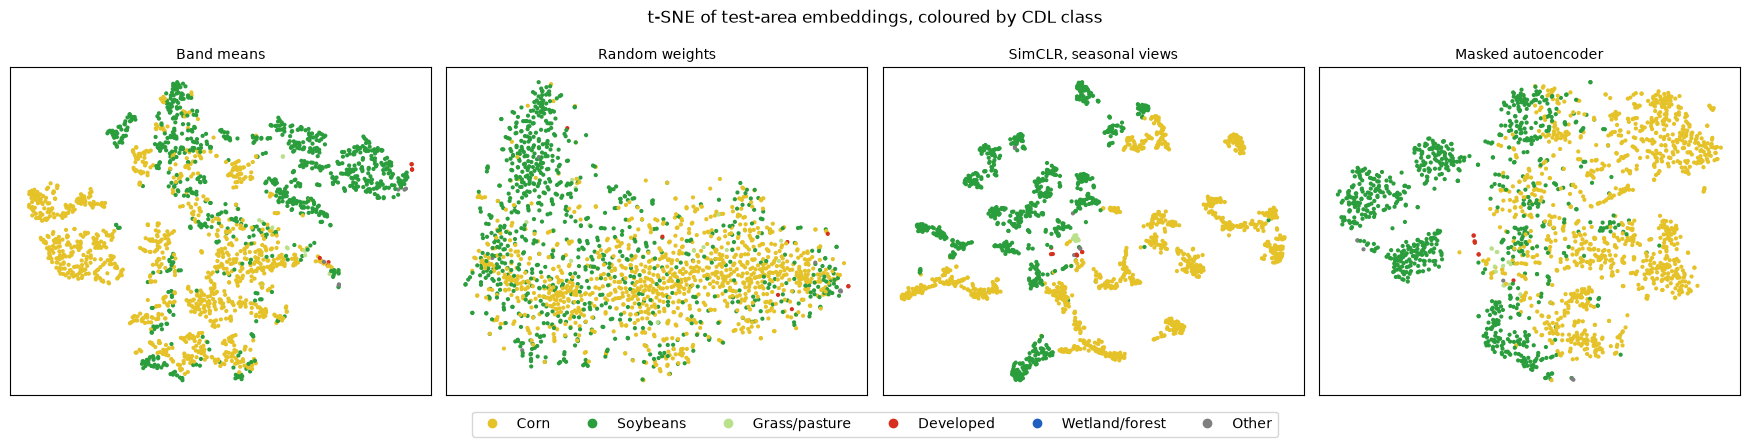

UMAP view skipped: install it with `pip install umap-learn`


In [18]:
view = ["Band means", "Random weights", "SimCLR, seasonal views", "Masked autoencoder"]  # feature sets shown
pick = np.random.default_rng(SEED).choice(np.flatnonzero(te), 2000, replace=False)  # 2,000 test chips
cmap_cls = ListedColormap(COLORS)  # class colours


def scatter_2d(project, title):  # one panel per feature set
    fig, ax = plt.subplots(1, len(view), figsize=(4.4 * len(view), 4.4))  # panels
    for a, name in zip(ax, view):  # each feature set
        E = emb[name][pick]  # its embeddings of the sample
        E = (E - E.mean(0)) / (E.std(0) + 1e-6)  # standardise the features
        xy = project(E)  # 2-D coordinates
        a.scatter(xy[:, 0], xy[:, 1], c=y_e[pick], cmap=cmap_cls, vmin=-0.5, vmax=K - 0.5, s=4)  # by class
        a.set_title(name, fontsize=10); a.set_xticks([]); a.set_yticks([])  # title, no ticks
    fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c) for c in COLORS],  # class legend
               labels=CLASSES, loc="lower center", ncol=K)  # class legend
    fig.suptitle(title); plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()  # arrange and draw


scatter_2d(lambda E: TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(E),  # t-SNE panels
           "t-SNE of test-area embeddings, coloured by CDL class")  # t-SNE panels
try:  # UMAP is optional
    import umap  # optional package umap-learn
    scatter_2d(lambda E: umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(E),  # UMAP panels
               "UMAP of test-area embeddings, coloured by CDL class")  # UMAP panels
except ImportError:  # not installed
    print("UMAP view skipped: install it with `pip install umap-learn`")  # say why it is missing

## Leakage between pretraining and test areas

SSL makes a new kind of leakage easy to miss. Pretraining needs no labels, so it is tempting to pretrain on **all** the imagery, including the area that will later be the test set. The encoder then learns the test fields' textures, boundaries and spectra before the evaluation, and the probe's test score no longer measures transfer to unseen land. The same applies to spatially random splits of the labelled chips, where test chips have neighbours from the same fields in the training set.

`check_geographic_overlap` measures, for every test chip, the distance to the nearest pretraining (or training) chip, and reports the share closer than a threshold. Here the threshold is the 1.6 km buffer. With the geographic holdout above, no test chip has a pretraining chip within the buffer; if the pretraining pool is the whole AOI, every test chip does.


In [19]:
test_xy = coords[loc_e[te]]  # centres of the test samples
pools = {  # name -> chip locations used for pretraining
    "geographic holdout (west only)": pretrain_loc,
    "whole AOI (includes the test area)": np.flatnonzero((usable.sum(axis=1) >= 2) & (region != 1)),
}
overlap = {}  # one row per pool
for name, locs in pools.items():  # each pool
    overlap[name] = ic.check_geographic_overlap(coords[locs], test_xy, min_distance=BUFFER_M)  # distances
    overlap[name]["pretraining chips"] = len(locs)  # pool size
overlap_table = pd.DataFrame(overlap).T  # as a table
overlap_table["fraction_within"] = overlap_table["fraction_within"].map("{:.1%}".format)  # as percent
overlap_table  # min/median distance (m) and share of test chips within the buffer

,min_distance,median_distance,fraction_within,pretraining chips
geographic holdout (west only),1920.0,6720.0,0.0%,5187.0
whole AOI (includes the test area),0.0,0.0,100.0%,8099.0


### Measure the effect of leaky pretraining

To see the effect, SimCLR with seasonal views is pretrained again with the same settings, on a pool drawn from the **whole AOI** (the same number of chips as the clean pool, so only the location changes). Both encoders are probed in the same way. A second comparison keeps the clean encoder but replaces the geographic split of the labelled chips with a **random** 70/30 split across the whole AOI.


In [20]:
rng = np.random.default_rng(SEED)  # random generator
leaky_pool = rng.choice(pools["whole AOI (includes the test area)"], len(pretrain_loc), replace=False)  # same size
t0 = time.time()  # start the timer
leaky_encoder, _ = ic.pretrain_contrastive(  # same recipe, leaky pool
    new_encoder(), make_loader(SeasonalPairs(leaky_pool)), in_channels=C, method="simclr",
    epochs=EPOCHS, lr=1e-3, temperature=0.2, proj_dim=64, device=DEVICE, seed=SEED, verbose=False)
print(f"leaky pretraining: {(time.time() - t0) / 60:.1f} min, "  # run time and share in the test area
      f"{(region[leaky_pool] == 2).mean():.0%} of its chips lie in the test area")


def probe_score(E, train_mask, test_mask):  # macro F1 and accuracy of a linear probe
    p = ic.linear_probe(E[train_mask], y_e[train_mask], E[test_mask], max_iter=3000)["predictions"]  # fit and predict
    r = ic.classification_report(y_e[test_mask], p, labels=list(range(K)))  # scores
    return {"overall accuracy": r["overall_accuracy"], "macro F1": r["macro_f1"]}  # the two scores


emb_leaky = ic.extract_embeddings(leaky_encoder, X_eval, batch_size=512, device=DEVICE)  # leaky features
clean = emb["SimCLR, seasonal views"]  # clean features
rand_test = np.random.default_rng(SEED).random(len(y_e)) < 0.3  # random 30 % of all samples as test
leak_rows = {  # three probe settings
    "clean pretraining, geographic split": probe_score(clean, tr, te),
    "leaky pretraining, geographic split": probe_score(emb_leaky, tr, te),
    "clean pretraining, random split": probe_score(clean, ~rand_test, rand_test),
}
pd.DataFrame(leak_rows).T.round(3)  # show the comparison

leaky pretraining: 1.7 min, 36% of its chips lie in the test area


,overall accuracy,macro F1
"clean pretraining, geographic split",0.987,0.610
"leaky pretraining, geographic split",0.989,0.632
"clean pretraining, random split",0.991,0.882


In this AOI the leaky encoder gains only a few tenths of a point of accuracy: the eastern and western thirds are the same flat, rotated corn-soybean landscape, so seeing the test fields during pretraining teaches the encoder little that the western fields did not. That is a property of this landscape, not a reason to skip the check. Where the test region differs more (another county, soil, climate or year), the leaky encoder has seen the target domain and the clean one has not, and the gap grows. The random split changes the test set itself: its test chips sit between training chips from the same fields, and it contains the western wetland and forest chips that the eastern test area lacks, so its macro F1 is not comparable with the geographic rows. Only the geographic numbers estimate performance in an area that was never seen.


## Export the encoders and an embedding map

### Save the encoders and write the embedding map

The encoder weights are saved with the normalisation statistics, so they can be reloaded with `make_encoder` / `build_mae` and `load_state_dict` to embed new chips or to fine-tune for another task. As a visual check of what an encoder learned, every chip of the AOI is embedded with the most accurate encoder on the clearest August 2025 date, the embeddings are reduced to three principal components, and these are written as a three-band, 320 m Cloud-Optimized GeoTIFF with `rs.write`. Chips that are cloudy on that date are left as nodata. Similar colours mean similar features. For comparison, the CDL 2025 classes, which the encoder never saw, are shown as the majority class of each chip on the same 320 m grid. In the feature map, two dominant colours follow the corn and soybean pattern of the CDL, a third traces the one-mile road grid (chips that straddle a section road), and another follows the stream valleys with their grass and trees: the encoder has organised the landscape without a single label.


wrote Tutorials/notebooks/09_remote_sensing/09_09_image_classification/data/Corn_belt/outputs/self_supervised/embedding_pca_20250826.tif and Tutorials/notebooks/09_remote_sensing/09_09_image_classification/data/Corn_belt/outputs/self_supervised/ssl_encoders_corn_belt.pt


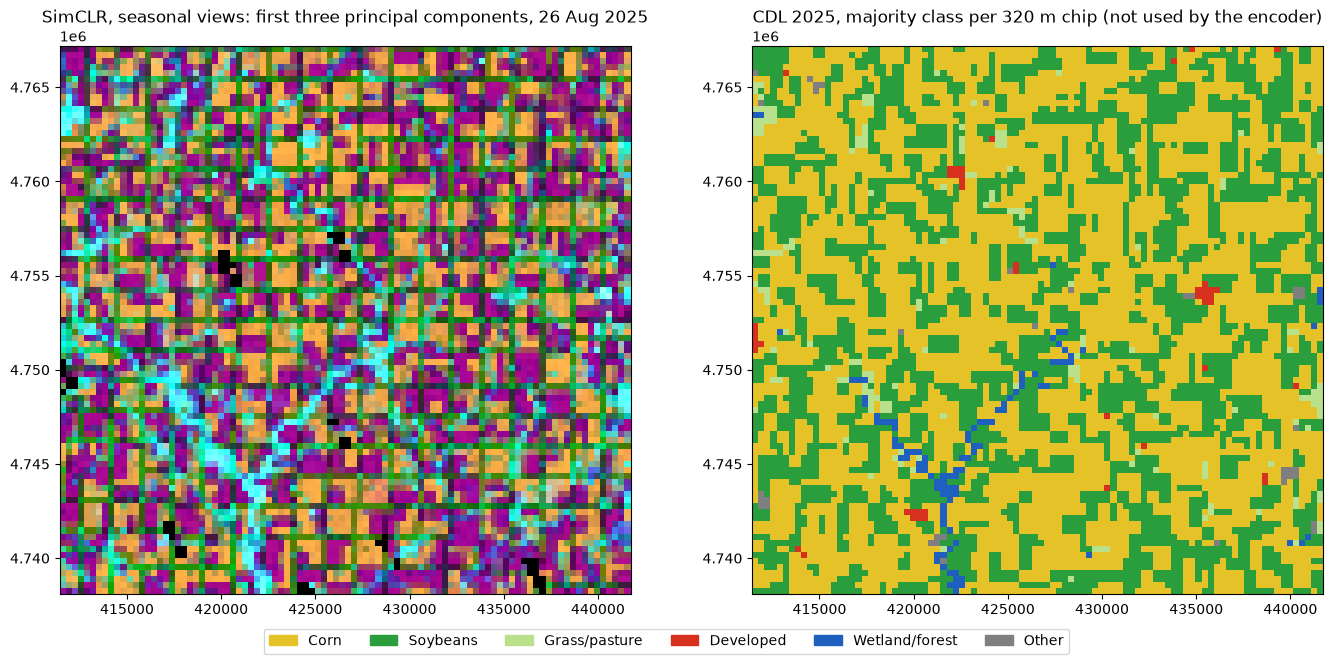

In [21]:
torch.save({"encoders": {n: e.state_dict() for n, e in encoders.items()},  # weights of every encoder
            "bands": BANDS, "mean": MEAN.ravel(), "std": STD.ravel(), "chip": CHIP},  # normalisation
           OUTPUT_DIR / "ssl_encoders_corn_belt.pt")  # one file
cand = np.flatnonzero(np.asarray((DATES.year == YEARS[-1]) & (DATES.month == 8)))  # August dates of the last year
t_map = int(cand[np.argmax(usable[:, cand].mean(axis=0))])  # the clearest one
ok = usable[:, t_map]  # chips clear on that date
map_encoder = probe_table.drop(index=["Band means", "Random weights"])["overall accuracy"].astype(float).idxmax()  # most accurate SSL encoder
E_map = ic.extract_embeddings(encoders[map_encoder], normalize(chips[ok, t_map]), batch_size=512, device=DEVICE)  # its features of every clear chip
pcs = PCA(3, random_state=SEED).fit_transform(E_map)  # three principal components
lo, hi = np.percentile(pcs, [2, 98], axis=0)  # 2-98 % stretch of each component
img = np.full((3, NR * NC), np.nan, "float32")  # nodata everywhere ...
img[:, ok] = np.clip((pcs - lo) / (hi - lo), 0, 1).T  # ... except on clear chips
emb_map = xr.DataArray(img.reshape(3, NR, NC), dims=("band", "y", "x"),  # the chip grid at 320 m
                       coords={"band": ["pc1", "pc2", "pc3"], "y": ys, "x": xs}, name="embedding_pca")
emb_map = emb_map.rio.write_crs(CRS).rio.write_nodata(np.nan)  # georeference it
emb_map.attrs = {"encoder": map_encoder, "date": f"{DATES[t_map]:%Y-%m-%d}", "chip_size_m": CHIP * 20}  # metadata
map_path = OUTPUT_DIR / f"embedding_pca_{DATES[t_map]:%Y%m%d}.tif"  # output file
rs.write(emb_map, map_path)  # Cloud-Optimized GeoTIFF
print("wrote", map_path.relative_to(ROOT), "and", (OUTPUT_DIR / "ssl_encoders_corn_belt.pt").relative_to(ROOT))  # files written

yl = len(YEARS) - 1  # index of the last CDL year
cdl_chip = np.where(labelled[:, yl] > 0, major[:, yl], np.nan).reshape(NR, NC)  # majority class of each chip
fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))  # two panels
ax[0].imshow(np.nan_to_num(img.reshape(3, NR, NC).transpose(1, 2, 0)), extent=ext, interpolation="nearest")  # components as RGB
ax[0].set_title(f"{map_encoder}: first three principal components, {DATES[t_map]:%d %b %Y}")  # title
ax[1].imshow(cdl_chip, cmap=cmap_cls, vmin=-0.5, vmax=K - 0.5, extent=ext, interpolation="nearest")  # CDL
ax[1].set_title(f"CDL {YEARS[-1]}, majority class per 320 m chip (not used by the encoder)")  # title
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES,  # class legend
           loc="lower center", ncol=K)  # class legend
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()  # arrange and draw

## Interpretation and limitations

- **Read the probe table against both baselines.** A random-weights ResNet already produces features a linear probe can use, and the ten band means already carry most of the spectral information for corn versus soybeans at peak season. Pretraining is worth its GPU time only where it beats both, which is usually clearest at small label budgets.
- **Seasonal views teach invariance to date.** Pairing two dates of one season tells the encoder that crop stage, illumination and haze do not change what a chip is. Pairing dates from different years would also teach invariance to the corn/soybean rotation, which is the signal crop mapping needs; that is why the pairs here stay within one season.
- **One peak-season image per sample.** The probe sees a single July or August image. Corn and soybeans are separated much better with a full time series (see `09_09_03_02`), so the absolute scores here are lower than a temporal classifier would reach; the comparison between encoders is the point.
- **Small encoders, short training.** ResNet-18 on 16-pixel chips and a small convolutional MAE trained for a few minutes are teaching-sized. Published models (SeCo, SSL4EO-S12, SatMAE, Prithvi) pretrain ViTs or ResNet-50s on millions of chips from around the world; their weights can be loaded through `load_foundation_encoder` and probed the same way.
- **Labels are 320 m chips with a majority class.** Mixed chips are excluded from evaluation, so the scores describe fairly pure chips, not field edges. The CDL itself has errors (its own accuracy for corn and soybeans in Iowa is high, but lower for minority classes).
- **Geographic holdout within one AOI.** The test area is 10 km from the training area's edge at most, in the same county-scale landscape. It measures transfer across this AOI, not to other regions, years outside 2020 to 2025, or other sensors.
- **GPU training is not bit-for-bit reproducible.** The seeds fix the data order and initial weights, but cuDNN kernels are non-deterministic, so a re-run moves the scores by up to about a point. Compare methods by their pattern, not by the third decimal.
- **Leakage checks are cheap; use them.** `check_geographic_overlap` should be run on every pretraining pool before the test numbers are trusted, and the distances reported with the results.

### References

- Chen, T., Kornblith, S., Norouzi, M., Hinton, G. (2020). A simple framework for contrastive learning of visual representations (SimCLR). ICML.
- He, K., Fan, H., Wu, Y., Xie, S., Girshick, R. (2020). Momentum contrast for unsupervised visual representation learning (MoCo). CVPR.
- He, K., Chen, X., Xie, S., Li, Y., Dollár, P., Girshick, R. (2022). Masked autoencoders are scalable vision learners. CVPR.
- Mañas, O., Lacoste, A., Giró-i-Nieto, X., Vazquez, D., Rodríguez, P. (2021). Seasonal Contrast: unsupervised pre-training from uncurated remote sensing data. ICCV.
- Cong, Y., Khanna, S., Meng, C., et al. (2022). SatMAE: pre-training transformers for temporal and multi-spectral satellite imagery. NeurIPS.
- Wang, Y., Braham, N. A. A., Xiong, Z., et al. (2023). SSL4EO-S12: a large-scale multimodal, multitemporal dataset for self-supervised learning in Earth observation. IEEE GRSM.
- USDA NASS Cropland Data Layer. https://www.nass.usda.gov/Research_and_Science/Cropland/
